### **Qus: Why required training into deep ?**

* vanishing gradients problem
* not have enough training data for such a large network, or it might be too costly to label
* training may be extremely slow
* model with millions of parameters would ***severely risk overfitting*** the training set, especially if there ***are not enough training instances, or they are too noisy***.

# Gradient clipping, Vanishing and Exploding gradients:

## Vanishing Gradient Problem in Machine Learning

The vanishing gradient problem occurs when gradients become too small as they propagate backward through a deep neural network, causing slow learning or stalled training in earlier layers.

Consider a simple **4-layer neural network** where the loss $L$ is backpropagated using **gradient descent:**

$$w_{\text{new}} = w_{\text{old}} - \alpha \frac{\partial L}{\partial w}$$

where $w$ represents weight parameters and $\alpha$ is the learning rate.

**Step 1: Backpropagation Using Chain Rule**

For a deep network, gradients are calculated using the **chain rule:**

$$\frac{\partial L}{\partial w_1} = \frac{\partial L}{\partial a_4} \cdot \frac{\partial a_4}{\partial a_3} \cdot \frac{\partial a_3}{\partial a_2} \cdot \frac{\partial a_2}{\partial w_1}$$

where:

* $a_i = \sigma(z_i)$ (activation output)
* $\sigma(x)$ is the **sigmoid activation function**:
* Its derivative:

$$\sigma'(x) = \sigma(x)(1 - \sigma(x))$$

**Step 2: Analyzing Gradient Magnitude**

For **sigmoid activation**, if $\sigma(x)$ outputs values near **0 or 1**, its derivative is:

$$\sigma'(x) \approx 0.01 \text{ (very small)}$$

Thus, when propagating through layers:

$$\text{Gradient} = (0.01) \times (0.01) \times (0.01) \times (0.01) = 0.00000001$$

The **gradient almost vanishes**, meaning **weights in earlier layers barely update**, leading to **slow learning**.


![Vanishing Gradient Problem in Machine Learning](image.png)

![Weight Initialization Techniques (Glorot and He Initialization) for Deep Neural Networks](image-1.png)

Looking at the logistic activation function (see Figure 11-1), you can see that when inputs become large (negative or positive), the **function saturates at 0 or 1, with a derivative extremely close to 0**. Thus **when backpropagation kicks in, it has virtually no gradient to propagate back through the network**, and what little gradient exists keeps getting diluted as backpropagation progresses down through the top layers, so there is really nothing left for the lower layers.

### **Weight Initialization Techniques (Glorot and He Initialization) for Deep Neural Networks**

**Qus: We know Vanishing Gradient problem. Where or in what situations its come from?**

While building and training neural networks, it is ***crucial to initialize the weights appropriately*** to ensure a model with high accuracy. ***If the weights are not correctly initialized, it may give rise to the Vanishing Gradient problem*** or the ***Exploding Gradient problem***. Hence, selecting an appropriate weight initialization strategy is critical when training DL models.


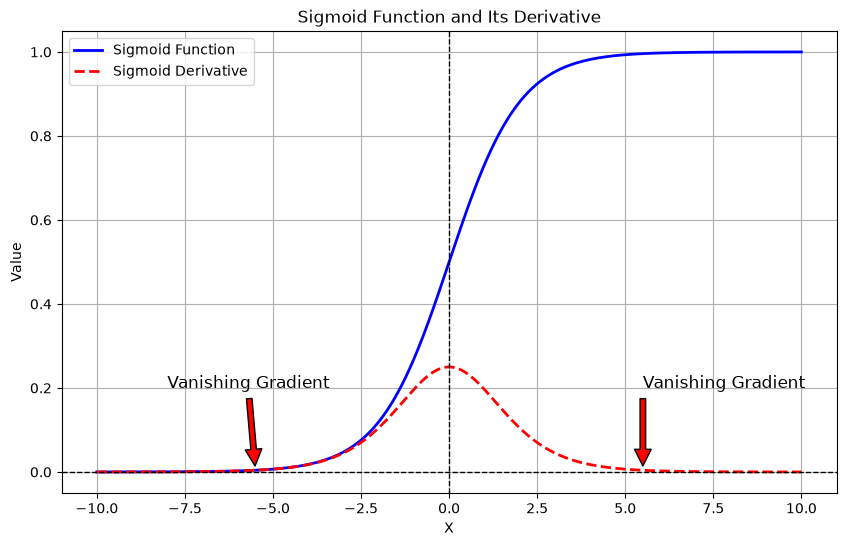

In [1]:
# Required Imports
import numpy as np
import matplotlib.pyplot as plt

# Sigmoid Function
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Linspace Function
def linspace(start, stop, num=50):
    return np.linspace(start, stop, num)

# Generate Data
X = linspace(-10, 10, 10000)

# Sigmoid Values
Y = sigmoid(X)

# Derivative of Sigmoid
Z = Y * (1 - Y)

# Plot
plt.figure(figsize=(10, 6))

plt.plot(X, Y,
         label='Sigmoid Function',
         color='blue',
         linewidth=2)

plt.plot(X, Z,
         label="Sigmoid Derivative",
         color='red',
         linestyle='--',
         linewidth=2)

plt.title('Sigmoid Function and Its Derivative')
plt.xlabel('X')
plt.ylabel('Value')

plt.axhline(0, color='black', lw=1, ls='--')
plt.axvline(0, color='black', lw=1, ls='--')

# Vanishing Gradient Annotations
plt.annotate(
    'Vanishing Gradient',
    xy=(5.5, 0.005),
    xytext=(5.5, 0.2),
    arrowprops=dict(facecolor='red', shrink=0.05),
    fontsize=12
)

plt.annotate(
    'Vanishing Gradient',
    xy=(-5.5, 0.005),
    xytext=(-8, 0.2),
    arrowprops=dict(facecolor='red', shrink=0.05),
    fontsize=12
)

plt.grid(True)
plt.legend()
plt.show()

**Terminology or Notations**

`fan_in` = Number of input paths towards the neuron  
`fan_out` = Number of output paths towards the neuron

**Weight Initialization Techniques:**

1. Zero Initialization:

   All the weights are assigned zero as the initial value is zero initialization. Rather, during any kind of constant initialization, the same issue happens to occur. Thus, ***constant initializations are not preferred***.

2. Random Initialization:

   Random initialization assigns random values except for zeros as weights to neuron paths. Assigning values randomly to the weights, problems such as Overfitting, Vanishing Gradient Problem, Exploding Gradient Problem might occur.

Before Going Random Initialization please understand Norman and Unifirm distro.

### **1. Normal Distribution (Gaussian)**

* **Shape:** Bell-shaped, symmetric around the mean.
* **Characteristics:**
  * Defined by **mean ($\mu$) and standard deviation ($\sigma$).**
  * Most values cluster around the center.
  * Tails extend infinitely in both directions.
* **Use Cases:**
  * Natural phenomena (e.g., height, test scores).
  * Assumed in many ML models due to the Central Limit Theorem.

**Probability Density Function (PDF):**

$$f(x) = \frac{1}{\sqrt{2\pi\sigma^2}} \cdot e^{-\frac{(x - \mu)^2}{2\sigma^2}}$$

### **2. Uniform Distribution**

* **Shape:** Flat — all outcomes are **equally likely**.
* **Characteristics:**
  * Defined by lower bound **a** and upper bound **b**.
  * Every value in $[a, b]$ has equal probability.
* **Use Cases:**
  * Random sampling.
  * Initialization of weights in some neural networks.

**Probability Density Function (PDF):**

$$f(x) = \frac{1}{b - a}, \quad \text{for } a \leq x \leq b$$

### **Visual Summary**

| Feature | Normal Distribution | Uniform Distribution |
| :--- | :--- | :--- |
| Shape | Bell curve (Gaussian) | Flat rectangle |
| Mean & Variance | Parameters ($\mu, \sigma^2$) | Midpoint and spread |
| Probability spread | Higher near mean | Equal across range |
| Common in ML | Yes (model assumptions) | Yes (initialization/sampling) |
| Symmetry | Symmetric | Symmetric (if centered) |



* Random Initialization can be of two kinds:

  * Random Normal :

    The weights are initialized from values in a normal distribution i.e. 0 mean and const variance.

    $w_i \sim N(0, 1)$

    ```python
    initializer = tf.keras.initializers.RandomNormal(
        mean=0., stddev=1.)
    layer = tf.keras.layers.Dense(3, kernel_initializer=initializer)
    ```

  * Random Uniform:

    The weights are initialized from values in a uniform distribution.

    $w_i \sim N(0, 1)$

    ```python
    initializer = tf.keras.initializers.RandomNormal(
        mean=0., stddev=1.)
    layer = tf.keras.layers.Dense(3, kernel_initializer=initializer)
    ```
3. Xavier/Glorot (uniform distribution) Initialization:

$w_i \sim U\left[-\sqrt{\frac{6}{\text{fan\_in} + \text{fan\_out}}}, \sqrt{\frac{6}{\text{fan\_in} + \text{fan\_out}}}\right]$

Suitable for layers where the activation **function used is Sigmoid.**

```python
initializer = tf.keras.initializers.GlorotUniform()
layer = tf.keras.layers.Dense(3, kernel_initializer=initializer)
```

4. Normalized Xavier/Glorot ( normal distribution) Initialization:

$w_i \sim N(0, \sigma)$

Here, $\sigma$ is given by:

$\sigma = \sqrt{\frac{6}{\text{fan\_in} + \text{fan\_out}}}$

```python
initializer = tf.keras.initializers.GlorotNormal()
layer = tf.keras.layers.Dense(3, kernel_initializer=initializer)
```

suitable for layers where the activation **function used is Sigmoid**

5. He Uniform Initialization:

$w_i \sim U\left[-\sqrt{\frac{6}{\text{fan\_in}}}, \sqrt{\frac{6}{\text{fan\_out}}}\right]$

Uniform Initialization is suitable for layers where ***ReLU activation function is used.***

```python
initializer = tf.keras.initializers.HeUniform()
layer = tf.keras.layers.Dense(3, kernel_initializer=initializer)
```

6. He Normal Initialization:

He Normal weight initialization, the weights are assigned from values of a normal distribution as follows.

$w_i \sim N[0, \sigma]$

Here, $\sigma$ is given by:

$\sigma = \sqrt{\frac{2}{\text{fan\_in}}}$

Uniform Initialization, too, is suitable for layers where ***ReLU activation function is used***

```python
initializer = tf.keras.initializers.HeNormal()
layer = tf.keras.layers.Dense(3, kernel_initializer=initializer)
```


### **Nonsaturating Activation Functions**

Nonsaturating activation functions are types of activation functions in neural networks ***that do not squash inputs into a narrow range (like 0 to 1)***. This means ***their derivatives don't shrink too much***, especially for large input values—thus helping to prevent the vanishing gradient problem.

Why Does This Matter?

* Faster convergence
* Better learning in deep networks
* Avoiding dead neurons

Examples of Nonsaturating Activation Functions:

| Activation | Formula | Notes |
| :--- | :--- | :--- |
| **ReLU** | $f(x) = \max(0, x)$ | Doesn't saturate for $x > 0$ |
| **Leaky ReLU** | $f(x) = \max(0.01x, x)$ | Small slope for $x < 0$ prevents dying neurons |
| **ELU** | $f(x) = x \text{ for } x > 0; \ \alpha(e^x - 1) \text{ for } x \leq 0$ | Smooth, helps with gradient flow |
| **Swish** | $f(x) = x \cdot \sigma(x)$ | Adaptive, nonsaturating, learned curve |



### **Qus: Explain Leaky ReLU non-saturating functions, how work work ?**

$$\text{LeakyReLU}_{\alpha}(z) = \max(\alpha z, z)$$

***hyperparameter $\alpha$ defines how much the function “leaks”:*** it is the slope of the function for $z < 0$, and is typically set to 0.01.

setting $\alpha = 0.2$ (huge leak) seemed to result in better performance than $\alpha = 0.01$ (small leak).

parametric leaky ReLU (PReLU), where $\alpha$ is authorized to be learned during training (instead of being a hyperparameter, it becomes a parameter that can be modified by backpropagation like any other parameter).

**Note: This was reported to strongly outperform ReLU on large image datasets, but on smaller datasets it runs the risk of overfitting the training set.**


![LeakyReLU activation function](image-2.png)
![ELU activation function](image-3.png)

The main drawback of the ELU activation function is that it is slower to compute than the ReLU and its variants (due to the use of the exponential function), but during training this is compensated by the faster convergence rate.

### **Self-Normalizing Neural Networks**

if you **build a neural network** composed exclusively of a stack of dense layers, and **if all hidden layers use the SELU activation function** (which is **just a scaled version of the ELU activation function**), then the **network will self-normalize**: the output of each layer will tend to **preserve mean 0 and standard deviation 1** during training, which **solves the vanishing/exploding gradients** problem.

Conditions for self-normalization to happen:

* The input features must be standardized (mean 0 and standard deviation 1).
* Every hidden layer's weights must also be initialized using LeCun normal initialization. In Keras, this means setting `kernel_initializer="lecun_normal"`.
* The network's architecture must be sequential. ???
* SELU activation function seems to work great with convolutional neural nets

**Qus: which activation function should you use for the hidden layers of your deep neural networks?**

***SELU > ELU > leaky ReLU (and its variants) > ReLU > tanh > logistic***

1. If the network's architecture prevents it from self-normalizing, then ELU may perform better than SELU.
2. If you care a lot about runtime latency, then you may prefer leaky ReLU.
3. If you don't want to tweak yet another hyperparameter, you may just use the default $\alpha$ values used by Keras (e.g., 0.3 for the leaky ReLU).
4. If you have spare time and computing power, you can use **cross-validation to evaluate other activation** functions, in particular RReLU if your network is overfitting, or PReLU if you have a huge training set

leaky ReLU activation function in Keras:

```python
leaky_relu = keras.layers.LeakyReLU(alpha=0.2)
layer = keras.layers.Dense(10, activation=leaky_relu,
                           kernel_initializer="he_normal")
```

set `activation="selu"` and `kernel_initializer="lecun_normal"` when creating a layer

```python
layer = keras.layers.Dense(10, activation="selu",
                           kernel_initializer="lecun_normal")
```



## **Exploding Gradients Problems**

* In deep neural networks, parameters are updated using gradient descent.
* The gradient of the loss with respect to weights is computed using the chain rule.
* If the derivatives in the chain are consistently greater than 1, multiplying them across many layers can cause the gradient to explode (become extremely large).
* This leads to unstable updates: weights oscillate or diverge instead of converging.

Consider a simple feedforward network with $n$ layers.
The gradient of the loss $L$ with respect to the weight $w_i$ in layer $i$ is:

$$\frac{\partial L}{\partial w_i} = \frac{\partial L}{\partial a_n} \cdot \frac{\partial a_n}{\partial a_{n-1}} \cdot \frac{\partial a_{n-1}}{\partial a_{n-2}} \cdots \frac{\partial a_1}{\partial w_i}$$

Suppose each derivative term is approximately **2** (instead of being close to 1).
Then for $n = 10$ layers:

$$\frac{\partial L}{\partial w_i} \approx 2^{10} = 1024$$

This means a single weight update could be scaled by **over 1000**, making the optimization unstable.

Concrete Example with Activation Function Take a network using the ReLU activation:

$$f(x) = \max(0, x), \quad f'(x) = 1 \ (\text{for } x > 0)$$

If weights are initialized with large values, say $w = 5$, then outputs grow quickly:

$$a_1 = w \cdot x, \quad a_2 = w \cdot a_1, \quad \dots, \quad a_n = w^n \cdot x$$

For $w = 5$, $n = 10$, and input $x = 1$:

$$a_{10} = 5^{10} \cdot 1 = 9,765,625$$

During backpropagation, gradients scale similarly:

$$\frac{\partial L}{\partial w} \sim w^n = 5^{10} = 9,765,625$$

This enormous gradient causes **exploding updates**, destabilizing training.

### **Problem Xavier Initialization Solves (The Xavier/Glorot Solution) [Constant Variance]**

The goal of Xavier initialization is to select the initial weights from a distribution (Uniform or Normal) such that **the variance of the activations and the variance of the gradients are preserved across every layer**. This ensures that the signal (and the learning) neither vanishes nor explodes as it flows forward and backward through the network.

1. **Xavier Normal Initialization (Gaussian Distribution):** Weights $W$ are sampled from a Normal distribution $\mathcal{N}(\mu, \sigma^2)$ with a mean $\mu = 0$ and a standard deviation $\sigma$ calculated as:

$$\sigma = \sqrt{\frac{2}{n_{in} + n_{out}}}$$

2. **Xavier Uniform Initialization (Uniform Distribution):** Weights $W$ are sampled from a Uniform distribution $U[-limit, limit]$, where the $limit$ is calculated as:

$$limit = \sqrt{\frac{6}{n_{in} + n_{out}}}$$

Where:

* $n_{in}$ (or $fan_{in}$) is **the number of input neurons** to the layer.
* $n_{out}$ (or $fan_{out}$) is **the number of output neurons** from the layer.

### **Why it Works for $tanh$ and Sigmoid:**

Both $tanh$ (range $[-1, 1]$) and $sigmoid$ (range $[0, 1]$) are roughly linear around the input value $z = 0$. The Xavier method, by maintaining the variance of the input signal to be around 1, ensures that most of the activations fall within this central, non-saturated, linear region. This keeps the gradients relatively large (close to 1), allowing the deep network to learn efficiently.

| Variant | Distribution | Formula for Spread |
| :--- | :--- | :--- |
| **Xavier Normal** | Weights $W$ drawn from a **Normal** distribution $\mathcal{N}(0, \sigma^2)$. | Standard Deviation: $\sigma = \sqrt{\frac{2}{n_{in} + n_{out}}}$ |
| **Xavier Uniform** | Weights $W$ drawn from a **Uniform** distribution $U[-limit, limit]$. | Limit (range): $limit = \sqrt{\frac{6}{n_{in} + n_{out}}}$ |

The denominator **$\mathbf{n_{in} + n_{out}}$** represents a compromise that balances keeping the forward signal variance constant (which requires $\propto 1/n_{in}$) and keeping the backward gradient variance constant (which requires $\propto 1/n_{out}$).

**Explain how the weight drawn from the normal distributions with 0 mean and sigma variance ?**

When we say weights are drawn from a normal distribution with mean 0 and variance $\sigma^2$, it means:

### **Output spatial size (after convolution)**

**Given:** input image $28 \times 28 \times 3$, one convolutional filter of size $4 \times 4$, padding $P = 0$, stride $S = 1$.

Use the standard 1-D formula applied to height and width:

$$\text{Out} = \left\lfloor \frac{W - F + 2P}{S} \right\rfloor + 1$$

Plugging numbers:

$$\text{Out} = \left\lfloor \frac{28 - 4 + 0}{1} \right\rfloor + 1 = 24 + 1 = 25$$

So **after the convolution** each filter produces a feature map of size $25 \times 25$.

Because you used **one filter**, the output tensor shape is $25 \times 25 \times 1$ (or in PyTorch batch/channel order: `[B, 1, 25, 25]`).

* **Mean $= 0 \rightarrow$ The distribution is centered around zero**, so weights are equally likely to be **positive or negative**.
* **Variance $= \sigma^2 \rightarrow$ Controls the spread of the weights.** Larger variance $\rightarrow$ weights more spread out; smaller variance $\rightarrow$ weights clustered near zero.
* Standard deviation $= \sigma \rightarrow$ Square root of variance, often used in practice.

Why This Matters in Neural Networks

* If weights are too large (large $\sigma$): activations and gradients can explode.
* If weights are too small (tiny $\sigma$): activations and gradients can vanish.
* Proper choice of $\sigma$ ensures stable forward and backward propagation.

Suppose we initialize weights for a layer with 100 inputs:

$$w_i \sim \mathcal{N}(0, \sigma^2)$$

The output of a neuron is:

$$z = \sum_{i=1}^{100} w_i x_i$$

* Expected value:

$$E[z] = \sum_{i=1}^{100} E[w_i] \cdot x_i = 0$$

* Variance:

**Variance of neurons:**

$$Var(z) = \sum_{i=1}^{100} Var(w_i) \cdot x_i^2 = \sigma^2 \sum_{i=1}^{100} x_i^2$$

👉 So the variance of the neuron's output depends directly on $\sigma^2$. **If $\sigma$ is too large, outputs blow up;** **if too small, outputs shrink.**

### **Practical Choices of $\sigma$**

* **Xavier Initialization (Glorot):**

$$w \sim \mathcal{N}\left(0, \frac{1}{n_{in}}\right)$$

Keeps variance stable across layers.

* **He Initialization (for ReLU):**

$$w \sim \mathcal{N}\left(0, \frac{2}{n_{in}}\right)$$

Accounts for ReLU's half-active behavior.


In [2]:
def analyze_layer_weights(weights):
    """
    weights: numpy array of shape (fan_out, fan_in)
    """
    fan_in = weights.shape[1]
    fan_out = weights.shape[0]
    
    mean = np.mean(weights)
    variance = np.var(weights)
    
    return {
        "fan_in": fan_in,
        "fan_out": fan_out,
        "mean": mean,
        "variance": variance
    }

# Example: layer with 128 inputs and 64 outputs
weights = np.random.randn(64, 128) * 0.01  # small random initialization
stats = analyze_layer_weights(weights)

print("Fan-in:", stats["fan_in"])
print("Fan-out:", stats["fan_out"])
print("Mean:", round(stats["mean"], 5))
print("Variance:", round(stats["variance"], 6))

Fan-in: 128
Fan-out: 64
Mean: -0.00017
Variance: 0.000101


## Qus: Explain how the Glorot weight initiations are differ from He norm & He uniform? Explain mathmetically?
Glorot (Xavier) Initialization use the average of fan in & out.

Normal distribution:

$$w \sim N\left(0, \frac{2}{n_{in} + n_{out}}\right)$$

And $f_{avg} = \frac{n_{in} + n_{out}}{2}$

So we can write

$$w \sim N\left(0, \frac{1}{f_{avg}}\right)$$

And the He init use

$$w \sim \mathcal{N}\left(0, \frac{2}{n_{in}}\right)$$

| distribution | Glorot (Xavier) Initialization | He Initialization |
| :--- | :--- | :--- |
| **Normal distribution:** | $w \sim \mathcal{N}\left(0, \frac{2}{n_{in} + n_{out}}\right)$ | $w \sim \mathcal{N}\left(0, \frac{2}{n_{in}}\right)$ |
| **Uniform distribution:** | $w \sim U\left[-\sqrt{\frac{6}{n_{in} + n_{out}}}, \sqrt{\frac{6}{n_{in} + n_{out}}}\right]$ | $w \sim U\left[-\sqrt{\frac{6}{n_{in}}}, \sqrt{\frac{6}{n_{in}}}\right]$ |

*You can see Glorot uses the average of $n_{in}$ and $n_{out}$.*
### **Why we use Nonsaturating Activation Functions in neural network ?**

We use nonsaturating activation functions *(like ReLU and its variants)* because they avoid the vanishing gradient problem, allow gradients to flow more freely, and make training deep networks more stable and efficient.

| Saturation functions | Nonsaturating Functions |
| :--- | :--- |
| `sigmoid`, `tanh` | `ReLU`, `Leaky ReLU`, `ELU`, `GELU` |

**Mathematical Contrast:**

* **Sigmoid:**

$$f(x) = \frac{1}{1 + e^{-x}}, \quad f'(x) = f(x)(1 - f(x))$$

* **For large $|x|$, $f'(x) \approx 0 \rightarrow$ gradient vanishes.**

* **ReLU:**

$$f(x) = \max(0, x), \quad f'(x) = 1 \ (\text{for } x > 0)$$

* **Gradient stays constant $\rightarrow$ no vanishing.**
### **Benefits of Nonsaturating Activations**

* Stable gradients $\rightarrow$ faster convergence.
* Efficient computation $\rightarrow$ simple piecewise linear function.
* Better performance in deep networks $\rightarrow$ allows training of hundreds of layers.
* Sparse activations $\rightarrow$ many neurons output 0, improving efficiency and reducing overfitting.

**Write mathematical equations: Leaky ReLU, ELU, GELU**

### **Leaky ReLU**

Leaky ReLU fixes the “dying ReLU” problem by allowing a small slope for negative inputs.

$$f(x) = \begin{cases} x & \text{if } x \geq 0 \\ \alpha x & \text{if } x < 0 \end{cases}$$

* $\alpha$ is a small constant (e.g., $0.01$).
* Derivative:

$$f'(x) = \begin{cases} 1 & \text{if } x \geq 0 \\ \alpha & \text{if } x < 0 \end{cases}$$
### **3. GELU (Gaussian Error Linear Unit)**

GELU uses a smooth probabilistic gating based on the Gaussian distribution.

$$f(x) = x \cdot \Phi(x)$$

Where $\Phi(x)$ is the **CDF of the standard normal distribution:**

$$\Phi(x) = \frac{1}{2} \left[ 1 + \text{erf}\left(\frac{x}{\sqrt{2}}\right) \right]$$

So explicitly:

$$f(x) = \frac{x}{2} \left[ 1 + \text{erf}\left(\frac{x}{\sqrt{2}}\right) \right]$$

* GELU smoothly interpolates between linear (ReLU-like) and saturating behavior.
* Often approximated in practice:

$$f(x) \approx 0.5x \left( 1 + \tanh\left( \sqrt{\frac{2}{\pi}} (x + 0.044715x^3) \right) \right)$$

* Leaky ReLU: Linear with small slope for negatives.
* ELU: Exponential curve for negatives, linear for positives.
* GELU: Smooth probabilistic gating using Gaussian CDF.


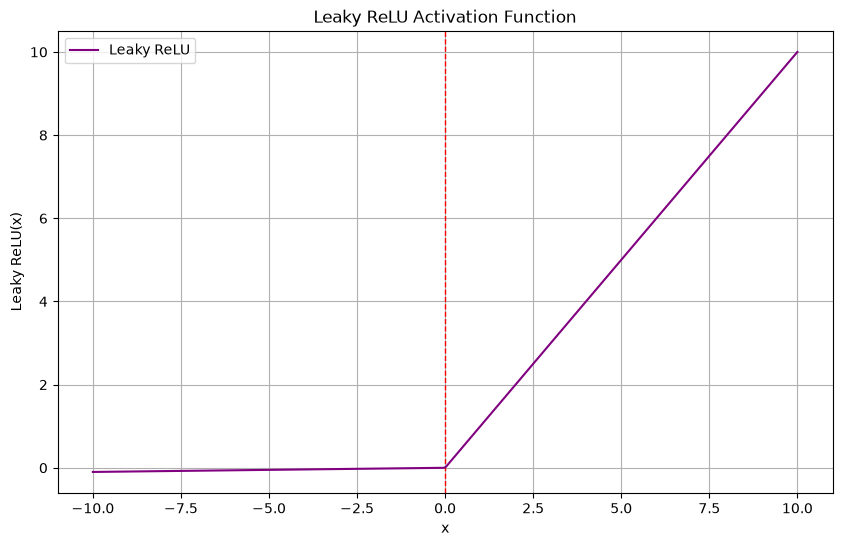

In [3]:
# Draw graph Leaky ReLU 
alpha = 0.01
def leaky_relu(x, alpha=alpha):
    return np.where(x > 0, x, alpha * x)
x = np.linspace(-10, 10, 400)
y_leaky_relu = leaky_relu(x)
#plot vertical line x = 0
plt.figure(figsize=(10, 6))
plt.axvline(x=0, color='red', linestyle='--', linewidth=1)
plt.plot(x, y_leaky_relu, label="Leaky ReLU", color="purple")
plt.title("Leaky ReLU Activation Function")
plt.xlabel("x")
plt.ylabel("Leaky ReLU(x)")
plt.legend()
plt.grid(True)
plt.show()

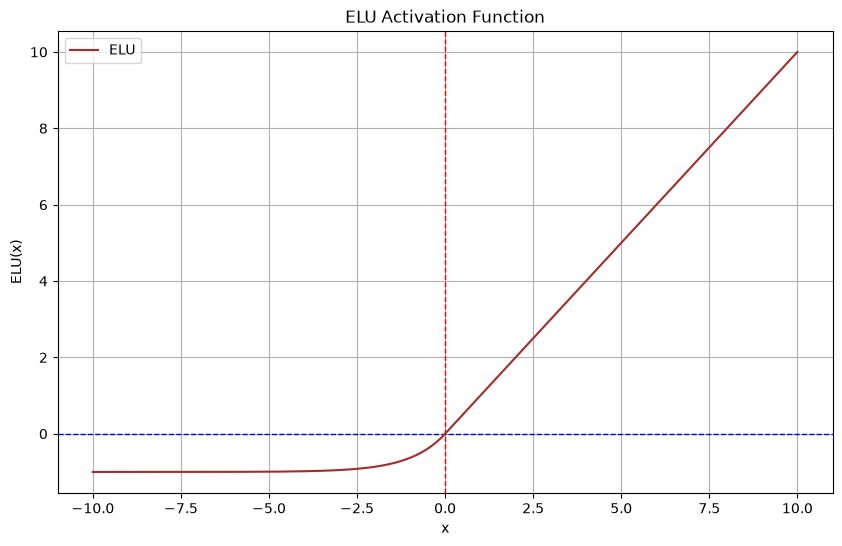

In [4]:
# Draw graph ELU
alpha = 1.0
def elu(x, alpha=alpha):
    return np.where(x > 0, x, alpha * (np.exp(x) - 1))
x = np.linspace(-10, 10, 400)
y_elu = elu(x)
plt.figure(figsize=(10, 6))
plt.axvline(x=0, color='red', linestyle='--', linewidth=1)
plt.axhline(y=0, color='blue', linestyle='--', linewidth=1)
plt.plot(x, y_elu, label="ELU", color="brown")
plt.title("ELU Activation Function")
plt.xlabel("x")
plt.ylabel("ELU(x)")
plt.legend()
plt.grid(True)
plt.show()

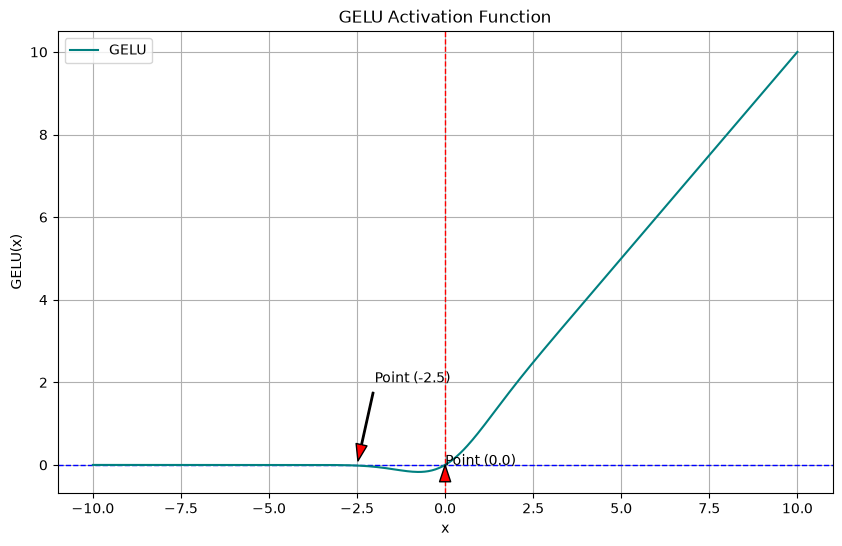

In [5]:
# Draw graph ELUGaussian Error Linear Unit
def gelu(x):
    return 0.5 * x * (1 + np.tanh(np.sqrt(2 / np.pi) * (x + 0.044715 * x**3)))  
x = np.linspace(-10, 10, 400)
y_gelu = gelu(x)
plt.figure(figsize=(10, 6))
# add annot -2.5 to 0
# Add annotation arrow at (2.5, 0)
plt.annotate(
    "Point (-2.5)",        # Text label
    xy=(-2.5, 0),             # Point to annotate
    xytext=(-2,2),          # Position of text
    arrowprops=dict(facecolor='red', shrink=0.05, width=1, headwidth=8)
)
plt.annotate(
    "Point (0.0)",        # Text label
    xy=(0.0, 0.0),             # Point to annotate
    xytext=(0,0),          # Position of text
    arrowprops=dict(facecolor='red', shrink=0.05, width=1, headwidth=8)
)
plt.axvline(x=0, color='red', linestyle='--', linewidth=1)
plt.axhline(y=0, color='blue', linestyle='--', linewidth=1)
plt.plot(x, y_gelu, label="GELU", color="teal")
plt.title("GELU Activation Function")
plt.xlabel("x")
plt.ylabel("GELU(x)")
plt.legend()
plt.grid(True)
plt.show()

## **Batch Normalization**

**Qus: if He initialization along with ELU (or any variant of ReLU) already present then why we required Batch Normalization technique ?**

He initialization along with ELU (or any variant of ReLU) can significantly reduce the vanishing/exploding gradients problems at the beginning of training, it **doesn't guarantee** that they won't come back during training.

Batch Normalization (BN) to address the vanishing/exploding gradients problems.

**Qus : how the Batch Normalization work ?**

The technique consists of adding an operation in the model just before or after the activation function of each hidden layer, simply zero-centering and normalizing each input, then scaling and shifting the result using two new parameter vectors per layer:

**one for scaling**, the **other for shifting**. In other words, this operation lets the model learn the optimal scale and mean of each of the layer's inputs.

*Equation 11-3. Batch Normalization algorithm*

1. $$\boldsymbol{\mu}_B = \frac{1}{m_B} \sum_{i=1}^{m_B} \mathbf{x}^{(i)}$$

2. $$\boldsymbol{\sigma}_B^2 = \frac{1}{m_B} \sum_{i=1}^{m_B} \left(\mathbf{x}^{(i)} - \boldsymbol{\mu}_B\right)^2$$

3. $$\widehat{\mathbf{x}}^{(i)} = \frac{\mathbf{x}^{(i)} - \boldsymbol{\mu}_B}{\sqrt{\boldsymbol{\sigma}_B^2 + \epsilon}}$$

4. $$\mathbf{z}^{(i)} = \boldsymbol{\gamma} \otimes \widehat{\mathbf{x}}^{(i)} + \boldsymbol{\beta}$$

* $\boldsymbol{\mu}_B$ is the vector of input means, evaluated over the whole mini-batch $B$ (it contains one mean per input).
* $\boldsymbol{\sigma}_B$ is the vector of input standard deviations, also evaluated over the whole minibatch (it contains one standard deviation per input).
* $\widehat{\mathbf{x}}^{(i)}$ is the vector of zero-centered and normalized inputs for instance $i$.
* $\boldsymbol{\gamma}$ is the output scale parameter vector for the layer (it contains one scale parameter per input).
* $\otimes$ represents element-wise multiplication (each input is multiplied by its corresponding output scale parameter).
* $\boldsymbol{\beta}$ is the output shift (offset) parameter vector for the layer (it contains one offset parameter per input). Each input is offset by its corresponding shift parameter.
* $\epsilon$ is a tiny number to avoid division by zero (typically $10^{-5}$). This is called a *smoothing term*.
* $\mathbf{z}^{(i)}$ is the output of the BN operation: it is a rescaled and shifted version of the inputs.
* $m_B$ is the number of instances in the mini-batch.

To see the effect of Batch Normalization on MNIST digit "0". Batch Normalization rescales activations to have mean = 0 and variance = 1, so the "after" histogram looks centered and standardized compared to the "before" histogram.

**Expected Result**

* Before BN: Histogram spread out, possibly skewed.
* After BN: Histogram centered at 0, variance normalized, smoother bell-like shape.

Note: I am not sure about the result. Need more research on it


24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


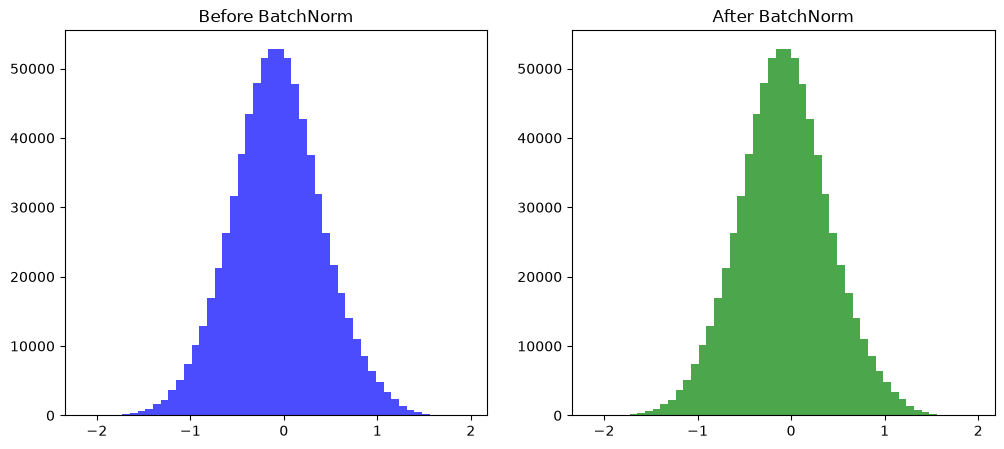

In [6]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from tensorflow.keras.layers import Dense, BatchNormalization, Input
from tensorflow.keras.models import Model


# 1. Load MNIST dataset
(x_train, y_train), (_, _) = mnist.load_data()

# 2. Filter only digit '0'
zeros = x_train[y_train == 0]
zeros = zeros.astype("float32") / 255.0  # normalize to [0,1]
zeros = zeros.reshape(len(zeros), -1)    # flatten (N, 784)

# 3. Define a simple dense layer
inputs = Input(shape=(784,))
dense = Dense(128, use_bias=False)(inputs)

# Model without BatchNorm
model_no_bn = Model(inputs, dense)

# Model with BatchNorm
bn_out = BatchNormalization()(dense)
model_bn = Model(inputs, bn_out)

# 4. Forward pass
activations_no_bn = model_no_bn.predict(zeros, batch_size=256)
activations_bn = model_bn.predict(zeros, batch_size=256)

# 5. Plot histograms
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.hist(activations_no_bn.flatten(), bins=50, color='blue', alpha=0.7)
plt.title("Before BatchNorm")

plt.subplot(1,2,2)
plt.hist(activations_bn.flatten(), bins=50, color='green', alpha=0.7)
plt.title("After BatchNorm")

plt.show()

### **Gradient Clipping**

Gradient Clipping is a technique used in machine learning—especially in training deep neural networks—to **prevent the exploding gradient problem**. When gradients become excessively large during backpropagation, they can cause unstable updates to model weights, leading to divergence or NaN values in the loss.

#### **How Gradient Clipping Works**

1. **Compute Gradients:** During backpropagation, gradients of the loss with respect to each parameter are calculated.
2. **Measure Gradient Norm:** The overall magnitude (norm) of the gradient vector is computed—often using the **L2 norm.**
3. **Compare to Threshold:** If the norm exceeds a predefined threshold, the gradients are **scaled down proportionally** so that the norm equals the threshold.

$\text{if } \Vert{}g\Vert{} > \tau, \quad g = \frac{\tau}{\Vert{}g\Vert{}} \cdot g$

where \(g\) is the gradient vector and \(\tau\) is the clipping threshold.

#### **Keras, Implementing Gradient Clipping**

In Keras, implementing Gradient Clipping is just a matter of setting the **clipvalue or clipnorm** argument when creating an optimizer. For example:

```python
optimizer = keras.optimizers.SGD(clipvalue=1.0)
model.compile(loss="mse", optimizer=optimizer)
```

If you set `clipnorm=1.0`, then the vector `[0.9, 100.0]` will be clipped to `[0.00899964, 0.9999595]`, preserving its orientation but almost eliminating the first component.

If you observe that the gradients explode during training (you can track the size of the gradients using TensorBoard), you may want to try both clipping by value and clipping by norm, with different threshold, and see which option performs best on the validation set.
